In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pymc as pm
import pymc_bart as pmb
import numpy as np
print(f"PyMC Version: {pm.__version__}")
print(f"PyMC-BART Version: {pmb.__version__}")
print(f"Numpy Version: {np.__version__}")

PyMC Version: 6.0.0
PyMC-BART Version: 0.12.0
Numpy Version: 2.0.2


In [3]:
import os
import psutil
import gc

def check_ram(label="Current"):
    # Get the OS-level memory footprint of this specific Jupyter kernel
    process = psutil.Process(os.getpid())
    mem_mb = process.memory_info().rss / (1024 * 1024)
    print(f"[{label}] RAM Usage: {mem_mb:,.2f} MB")

# Check the baseline with all_trees still sitting in memory
check_ram("BEFORE NUKE")

[BEFORE NUKE] RAM Usage: 264.12 MB


In [2]:
import warnings
# Suppress PyTensor FutureWarnings
warnings.filterwarnings("ignore", module="pytensor")
# Suppress ArviZ MigrationWarnings
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")

In [3]:
from importlib import reload
from bart_survival import surv_bart as sb
from bart_survival import simulation
import numpy as np
import time


Applying 1D-Flattened Patch with RNG Burn-Off Breakout...


In [4]:
rng = np.random.default_rng(1)
x_mat = simulation.get_x_matrix(
    N=500,
    x_vars=1,
    VAR_CLASS=[2],
    VAR_PROB=[.5],
    rng = rng
)
event_dict, sv_true, sv_scale_true = simulation.simulate_survival(
    x_mat = x_mat,
    scale_f = "np.exp(2 + .6*x_mat[:,0])",
    shape_f = "1",
    eos = 20,
    cens_scale=None,
    time_scale = 1,
    true_only=False,
    rng = rng
)
# prepare data
# t_scale = sb.get_time_transform(event_dict["t_event"], time_scale = 5)
# y_sk = sb.get_y_sklearn(event_dict["status"], t_scale)
trn = sb.get_surv_pre_train(
    y_status=event_dict["status"],
    y_time=event_dict["t_event"],
    x = x_mat, 
    weight=None,
    time_scale = 1
    )
post_test = sb.get_posterior_test(
    y_status=event_dict["status"],
    y_time=event_dict["t_event"],
    x = x_mat,
    time_scale = 1)

SPLIT_RULES =  [
    "pmb.ContinuousSplitRule()", # time
    # "pmb.OneHotSplitRule", # ccsr_ind_p2
    "pmb.ContinuousSplitRule()", # ccsr_ind_p2
]
model_dict = {"trees": 20,
    "split_rules": SPLIT_RULES
}
sampler_dict = {
            "draws": 250,
            "tune": 500,
            "cores": 4,
            "chains": 4,
            "compute_convergence_checks": False
        }

BSM = sb.BartSurvModel(model_config=model_dict, sampler_config=sampler_dict)
print(trn["y"].shape)


mean shape 1.0
mean scale 10.31705279211689
mean time draws 9.730650942888069
HI2
(4424, 1)


In [5]:
check_ram()

[Current] RAM Usage: 267.22 MB


In [6]:
start = time.perf_counter()
BSM.fit(
    y =  trn["y"],
    X = trn["x"],
    weights=trn["w"],
    coords = trn["coord"],
    random_seed=5
)

end = time.perf_counter()
print(f'TIME: {end - start:0.4f}')


# post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
# sv_prob = sb.get_sv_prob(post1)




Multiprocess sampling (4 chains in 4 jobs)
PGBART: [f]


Output()

Sampling 4 chains for 500 tune and 250 draw iterations (2_000 + 1_000 draws total) took 11 seconds.


TIME: 12.2018


In [9]:
del BSM.idata

SyntaxError: invalid syntax (1376856797.py, line 1)

In [ ]:
check_ram()

[Current] RAM Usage: 748.61 MB


In [20]:
# BSM.sample_posterior_predictive()
post1 = BSM.bart_predict(X_pred=post_test["post_x"], coords=post_test["coords"])
sv_prob1 = sb.get_sv_prob(post1)


In [21]:
post2 = BSM.predict_posterior(X_pred=post_test["post_x"], coords=post_test["coords"])
sv_prob2 = sb.get_sv_prob(post2)

In [22]:
import numpy as np
from numba import njit

# 1. Grab the very first patient's raw data directly from your training set
# (This guarantees the column order is 100% correct)
X_np = trn["x"].astype(np.float64) 
pt_0 = X_np[0] 

# 2. Extract the Numba Matrices
F_matrices = BSM.idata.bart_trees["feature"].values
T_matrices = BSM.idata.bart_trees["threshold"].values
L_matrices = BSM.idata.bart_trees["left"].values
R_matrices = BSM.idata.bart_trees["right"].values
V_matrices = BSM.idata.bart_trees["value"].values

# 3. Safely isolate Chain 0, Draw 0, Tree 0
if F_matrices.ndim == 4:
    f_tree0, t_tree0, l_tree0, r_tree0, v_tree0 = (
        F_matrices[0, 0, 0], T_matrices[0, 0, 0], L_matrices[0, 0, 0], R_matrices[0, 0, 0], V_matrices[0, 0, 0]
    )
else:
    f_tree0, t_tree0, l_tree0, r_tree0, v_tree0 = (
        F_matrices[0, 0], T_matrices[0, 0], L_matrices[0, 0], R_matrices[0, 0], V_matrices[0, 0]
    )

# 4. Numba Engine Micro-Function
@njit
def _eval_tree(x_row, f_tree, t_tree, l_tree, r_tree, v_tree):
    node = 0
    while f_tree[node] != -1:
        feat = f_tree[node]
        if x_row[feat] <= t_tree[node]:
            node = l_tree[node]
        else:
            node = r_tree[node]
    return v_tree[node]

# 5. Pure Python PyMC-BART Traversal
def py_eval_single_tree(tree, x_row):
    nodes = tree.tree_structure
    current_idx = 0
    while not nodes[current_idx].is_leaf_node():
        node = nodes[current_idx]
        feat = node.idx_split_variable
        split_val = node.value
        
        if x_row[feat] <= split_val:
            current_idx = 2 * current_idx + 1  # Go Left
        else:
            current_idx = 2 * current_idx + 2  # Go Right
            
    return float(np.atleast_1d(nodes[current_idx].value)[0])

# 6. RUN THE RACE
test_tree = BSM.all_trees[0][0][0] # Native Chain 0, Draw 0, Tree 0

py_val = py_eval_single_tree(test_tree, pt_0)
nb_val = _eval_tree(pt_0, f_tree0, t_tree0, l_tree0, r_tree0, v_tree0)

print("--- SINGLE TREE ATOMIC TEST ---")
print(f"PyMC-BART Tree 0 Output: {py_val}")
print(f"Numba Engine Tree 0 Output:  {nb_val}")

--- SINGLE TREE ATOMIC TEST ---
PyMC-BART Tree 0 Output: 0.059901716335338445
Numba Engine Tree 0 Output:  0.059901716335338445


In [23]:
# Assuming you saved the outputs as `old_preds` and `new_preds`
print("--- OVERALL POSTERIOR MEAN ---")
print(f"Old PyMC-BART Mean: {float(post1.mean()):.6f}")
print(f"New Numba Engine Mean: {float(post2['mu'].mean()):.6f}")

print("\n--- PATIENT 0 EXPECTED VALUE ---")
print(f"Old PyMC-BART Pt 0: {float(post1.isel(p_obs=200).mean()):.6f}")
print(f"New Numba Engine Pt 0: {float(post2['mu'].isel(p_obs=200).mean()):.6f}")

--- OVERALL POSTERIOR MEAN ---
Old PyMC-BART Mean: 0.102430
New Numba Engine Mean: 0.102292

--- PATIENT 0 EXPECTED VALUE ---
Old PyMC-BART Pt 0: 0.080177
New Numba Engine Pt 0: 0.079755


predicted_f

In [27]:
# pdp
pdp1 = sb.get_pdp(x_mat, var_col = [0], values = [[0,1]], sample_n = None)
pdp_tst = sb.get_posterior_test(
    y_status=event_dict["status"], 
    y_time=event_dict["t_event"],
    x = pdp1[0])
pdp_post = BSM.bart_predict(pdp_tst["post_x"], pdp_tst["coords"])

sv_prob = sb.get_sv_prob(pdp_post)
msk_1 = pdp1[1]["coord"] == 1
HR = (sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)).mean(0)
HR_QT = np.quantile((sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)),[0.025,0.975])


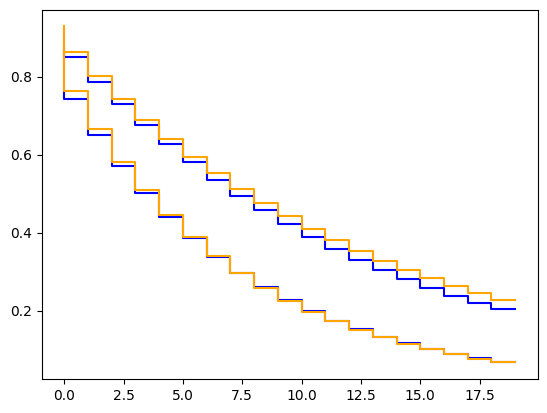

In [28]:
import matplotlib.pyplot as plt
plt.step(range(20), sv_prob["sv"][:,1:500,:].mean(1).mean(0), color="blue")
plt.step(range(20), sv_prob["sv"][:,501:1000,:].mean(1).mean(0), color="blue")

plt.step(range(20), sv_true["sv_true"][(x_mat==1).flatten(), :].mean(0), color="orange")
plt.step(range(20), sv_true["sv_true"][(x_mat==0).flatten(), :].mean(0), color="orange")
# sv_prob["sv"][1001:2000].mean(0)

In [29]:
# pdp
pdp1 = sb.get_pdp(x_mat, var_col = [0], values = [[0,1]], sample_n = None)
pdp_tst = sb.get_posterior_test(
    y_status=event_dict["status"], 
    y_time=event_dict["t_event"],
    x = pdp1[0])
pdp_post = BSM.predict_posterior(pdp_tst["post_x"], pdp_tst["coords"])

sv_prob = sb.get_sv_prob(pdp_post)
msk_1 = pdp1[1]["coord"] == 1
HR = (sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)).mean(0)
HR_QT = np.quantile((sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)),[0.025,0.975])


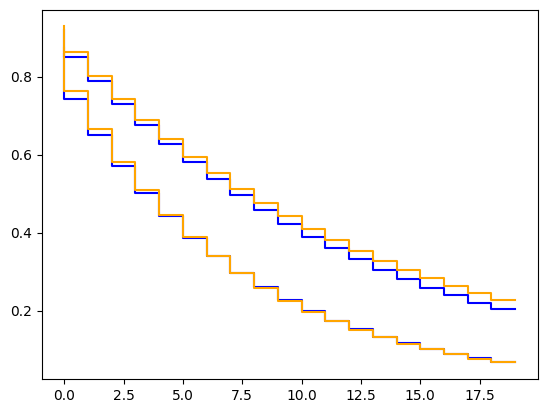

In [30]:
import matplotlib.pyplot as plt
plt.step(range(20), sv_prob["sv"][:,1:500,:].mean(1).mean(0), color="blue")
plt.step(range(20), sv_prob["sv"][:,501:1000,:].mean(1).mean(0), color="blue")

plt.step(range(20), sv_true["sv_true"][(x_mat==1).flatten(), :].mean(0), color="orange")
plt.step(range(20), sv_true["sv_true"][(x_mat==0).flatten(), :].mean(0), color="orange")

In [34]:
# Flatten the feature array and look for the highest index that isn't -1
# (Since each tree is spaced by MAX_NODES, we use modulo to find the local depth)
f_flat = BSM.idata.bart_trees["feature"].values.flatten()
active_indices = np.where(f_flat != -1)[0]
max_local_index = np.max(active_indices % 255)

print(f"The deepest node used in any tree was index: {max_local_index}")

The deepest node used in any tree was index: 3


In [46]:
py_patient_means[abs(py_patient_means - nb_patient_means) > 0.01]
nb_patient_means[abs(py_patient_means - nb_patient_means) > 0.01]
wrongs = post_test["post_x"][abs(py_patient_means - nb_patient_means) > 0.01]
rights = post_test["post_x"][abs(py_patient_means - nb_patient_means) <= 0.01]

In [49]:
print("baseline unique observations")
print(np.unique(post_test["post_x"], axis=0))

wrongs = post_test["post_x"][abs(py_patient_means - nb_patient_means) > 0.01]
rights = post_test["post_x"][abs(py_patient_means - nb_patient_means) <= 0.01]
print('unique observations that were > 0.01 difference between py and nb preds')
print(np.unique(wrongs,axis=0))
print('unique observations that were >= 0.01 difference between py and nb preds')
print(np.unique(rights,axis=0))

baseline unique observations
[[ 1.  0.]
 [ 1.  1.]
 [ 2.  0.]
 [ 2.  1.]
 [ 3.  0.]
 [ 3.  1.]
 [ 4.  0.]
 [ 4.  1.]
 [ 5.  0.]
 [ 5.  1.]
 [ 6.  0.]
 [ 6.  1.]
 [ 7.  0.]
 [ 7.  1.]
 [ 8.  0.]
 [ 8.  1.]
 [ 9.  0.]
 [ 9.  1.]
 [10.  0.]
 [10.  1.]
 [11.  0.]
 [11.  1.]
 [12.  0.]
 [12.  1.]
 [13.  0.]
 [13.  1.]
 [14.  0.]
 [14.  1.]
 [15.  0.]
 [15.  1.]
 [16.  0.]
 [16.  1.]
 [17.  0.]
 [17.  1.]
 [18.  0.]
 [18.  1.]
 [19.  0.]
 [19.  1.]
 [20.  0.]
 [20.  1.]]
unique observations that were > 0.01 difference between py and nb preds
[[ 1.  0.]
 [ 2.  0.]
 [ 3.  0.]
 [ 4.  0.]
 [ 5.  0.]
 [ 6.  0.]
 [ 7.  0.]
 [ 8.  0.]
 [ 9.  0.]
 [10.  0.]
 [11.  0.]
 [12.  0.]
 [13.  0.]
 [14.  0.]
 [15.  0.]
 [16.  0.]
 [17.  0.]
 [18.  0.]
 [19.  0.]
 [20.  0.]]
unique observations that were >= 0.01 difference between py and nb preds
[[ 1.  1.]
 [ 2.  1.]
 [ 3.  1.]
 [ 4.  1.]
 [ 5.  1.]
 [ 6.  1.]
 [ 7.  1.]
 [ 8.  1.]
 [ 9.  1.]
 [10.  1.]
 [11.  1.]
 [12.  1.]
 [13.  1.]
 [14.  1.]
 [15.  1.]

In [ ]:
# pdp
pdp1 = sb.get_pdp(x_mat, var_col = [0], values = [[0,1]], sample_n = None)
pdp_tst = sb.get_posterior_test(
    y_status=event_dict["status"], 
    y_time=event_dict["t_event"],
    x = pdp1[0])
pdp_post = BSM.sample_posterior_predictive(pdp_tst["post_x"], pdp_tst["coords"])

sv_prob = sb.get_sv_prob(pdp_post)
msk_1 = pdp1[1]["coord"] == 1
HR = (sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)).mean(0)
HR_QT = np.quantile((sv_prob["prob"][:,msk_1,:].mean(1) / sv_prob["prob"][:,~msk_1,:].mean(1)),[0.025,0.975])

# allow 20% difference
# assert(.2 > np.abs(np.exp(-.4) - HR.mean()))

print(HR)

In [ ]:
sv_true

In [ ]:
np.exp(-.4)

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
# assert(.1>np.abs((sv_prob["sv"].mean(0)-sv_scale_true["sv_true"]).mean()))
plt.step(np.arange(20), sv_prob["sv"].mean(1).mean(0), where="post")
np.quantile(sv_prob["sv"].mean(1), [0.025, 0.975], axis=0)

In [ ]:
# 1. Let's look at the raw Z predictions before they get crushed to 1.0
post1 = BSM.sample_posterior_predictive(X_pred=post_test["post_x"], coords=post_test["coords"])
# Pull the raw values we just calculated
mu_raw = post1["mu"].to_numpy()
print(f"Mu min: {mu_raw.min():.4f}, Mu max: {mu_raw.max():.4f}")
print(f"Offset used: {BSM.idata['bart_metadata']['offset'].values}")

# 2. Let's peek inside exactly ONE tree to verify my heap math
first_tree = BSM.all_trees[0][0][0]
print("\nTree Keys:", first_tree.tree_structure.keys())
for k, v in first_tree.tree_structure.items():
    # Print the node index, if it's a leaf, and the raw value
    val = float(np.atleast_1d(v.value)[0])
    print(f"Node {k}: Leaf={v.is_leaf_node}, Value={val:.4f}")
    if len(first_tree.tree_structure) > 10 and k > 10: 
        break # Just print the first few nodes!

In [ ]:
trn["x"]

In [ ]:
post_test["post_x"]

In [ ]:
import lifelines as ll
km = ll.KaplanMeierFitter()
km.fit(event_dict["t_event"], event_dict["status"])
km.plot()
plt.step(np.arange(20), sv_prob["sv"].mean(1).mean(0), where="post")

In [ ]:
post1

In [ ]:
first_tree = BSM.model.f.owner.op.all_trees[0][0][0]

# Print all the available attributes so we can see where the root node is hiding
print(dir(first_tree))

In [ ]:
# Grab the very first tree from the first draw of the first chain
first_tree = BSM.model.f.owner.op.all_trees[0][0][0]

# Get the root node (assuming index 0)
root_node = first_tree.get_node(0)

# Print the node's properties
print(dir(root_node))

In [ ]:
all_chains = BSM.model["f"].owner.op.all_trees
all_draws = [draw for chain in all_chains for draw in chain]
for draw_trees in all_draws:
    for tree in draw_trees:
        print(dir(tree))

In [ ]:
import pymc
pymc.__version__

In [ ]:
import pymc_bart
pymc_bart.__version__